In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [5]:
print(df.shape)

(891, 12)


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
print(df.duplicated().sum())

0


In [9]:
df["Age"] = df["Age"].fillna(df["Age"].mean())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [22]:
df.drop("Cabin", axis=1, inplace=True)

In [23]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

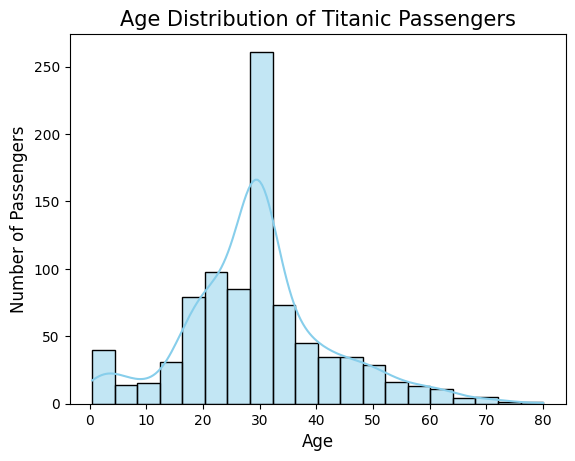

In [11]:
plt.Figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x = "Age",
    bins=20,
    kde=True,
    color='skyblue',
    edgecolor = 'black'
)

plt.title("Age Distribution of Titanic Passengers", fontsize=15)
plt.xlabel("Age",fontsize=12)
plt.ylabel("Number of Passengers",fontsize=12)

plt.savefig("age_distribution_histogram.png", dpi=300, bbox_inches='tight')
plt.show()

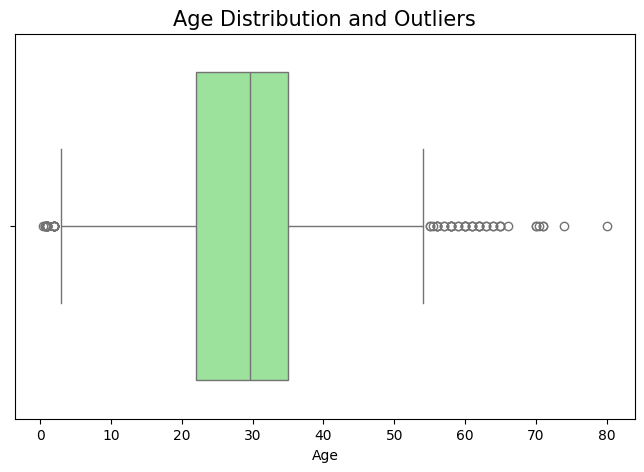

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Age",
    color="lightgreen"
)

plt.title("Age Distribution and Outliers", fontsize=15)
plt.xlabel("Age")

plt.savefig("age_boxplot.png", dpi=300)
plt.show()

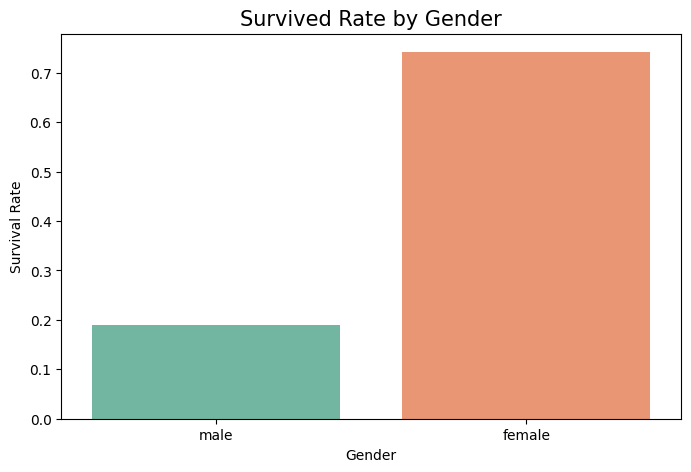

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Sex",
    y="Survived",
    hue="Sex",
    palette="Set2",
    errorbar=None
)
plt.title("Survived Rate by Gender", fontsize=15)
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.savefig("gender_survival_bar.png", dpi=300)
plt.show()

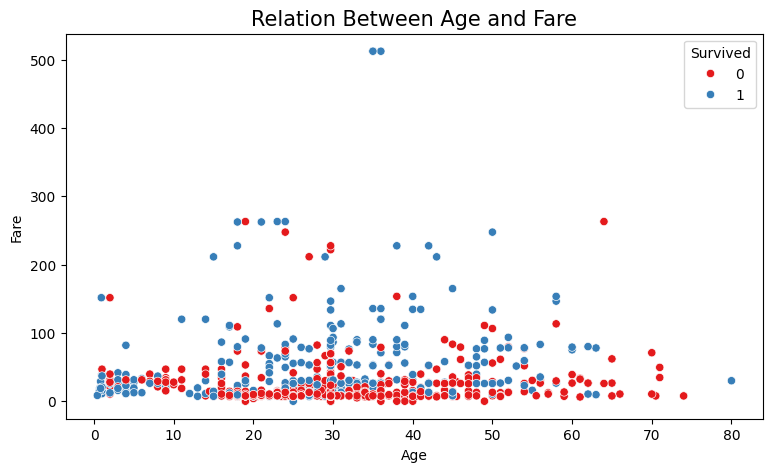

In [14]:
plt.figure(figsize=(9,5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Fare",
    hue="Survived",
    palette="Set1",
)

plt.title("Relation Between Age and Fare", fontsize=15)
plt.xlabel("Age")
plt.ylabel("Fare")

plt.savefig("age_fare_scatter.png", dpi=300)
plt.show()

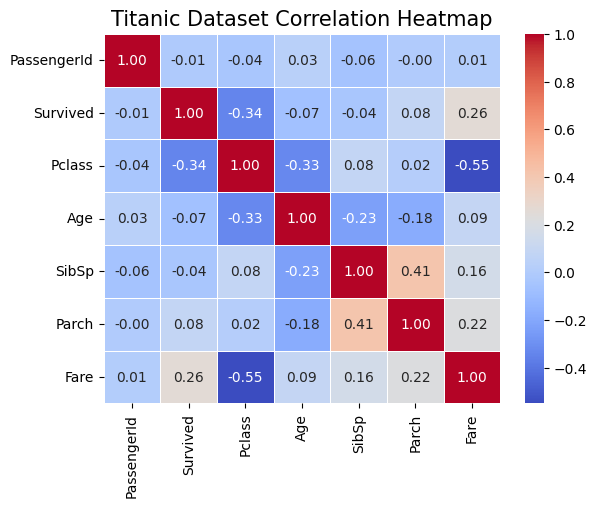

In [15]:
plt.Figure(figsize=(10,7))

numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Titanic Dataset Correlation Heatmap", fontsize=15)

plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

Feature Selection

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df.drop(['PassengerId', 'Name', 'Ticket'], axis=1, inplace=True)

X = df.drop('Survived', axis=1)
y = df['Survived']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (891, 7)
Target Shape: (891,)


In [37]:
from sklearn.model_selection import train_test_split

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_test: (179, 7)
y_train: (712,)
y_test: (179,)


In [40]:
X_train = pd.get_dummies(X_train, columns=["Sex", "Embarked"], drop_first=True)
X_test = pd.get_dummies(X_test, columns=["Sex", "Embarked"], drop_first=True)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print(X_train.head())

Training Shape: (712, 8)
Testing Shape: (179, 8)
     Pclass        Age  SibSp  Parch      Fare  Sex_male  Embarked_Q  \
692       3  29.699118      0      0   56.4958      True       False   
481       2  29.699118      0      0    0.0000      True       False   
527       1  29.699118      0      0  221.7792      True       False   
855       3  18.000000      0      1    9.3500     False       False   
801       2  31.000000      1      1   26.2500     False       False   

     Embarked_S  
692        True  
481        True  
527        True  
855        True  
801        True  


In [41]:
from sklearn.tree import DecisionTreeClassifier

In [43]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)
model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [44]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual":y_test.values,
    "Predict":y_pred
})
print(results.head(10))

   Actual  Predict
0       0        0
1       0        0
2       1        0
3       0        0
4       1        1
5       1        0
6       1        1
7       0        0
8       0        0
9       0        0


In [45]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

print("Module Accuracy:", accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Rreport:")
print(classification_report(y_test, y_pred))

Module Accuracy: 78.77094972067039 %

Confusion Matrix:
[[103   7]
 [ 31  38]]

Classification Rreport:
              precision    recall  f1-score   support

           0       0.77      0.94      0.84       110
           1       0.84      0.55      0.67        69

    accuracy                           0.79       179
   macro avg       0.81      0.74      0.76       179
weighted avg       0.80      0.79      0.78       179



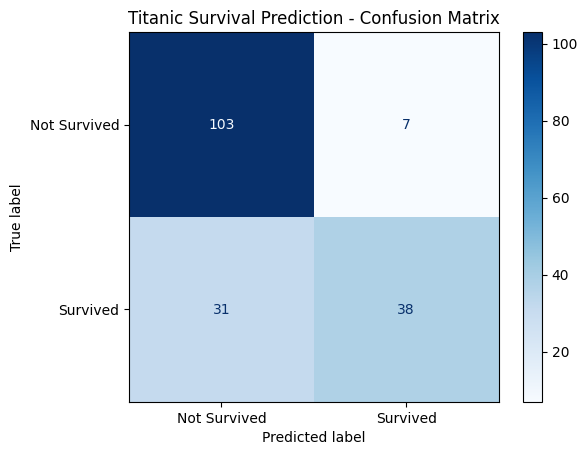

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Not Survived', 'Survived'],
    cmap='Blues'
)

plt.title('Titanic Survival Prediction - Confusion Matrix')
plt.show()

In [47]:
from sklearn.tree import plot_tree

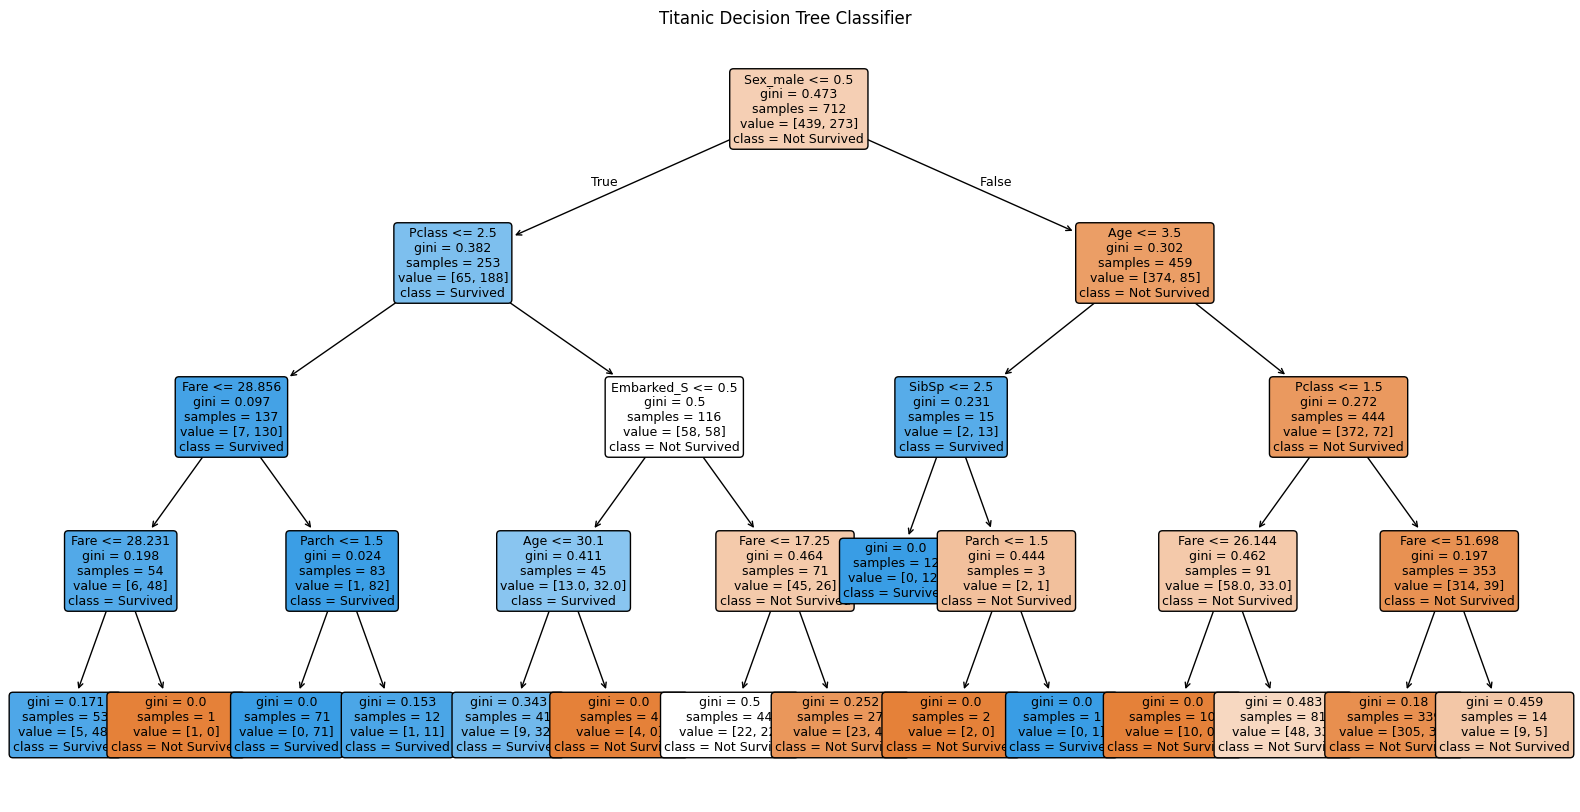

In [48]:
plt.figure(figsize=(20, 10))

plot_tree(
    model, feature_names=X_train.columns,
    class_names=['Not Survived', 'Survived'],
    filled=True, rounded=True, fontsize=9
)

plt.title("Titanic Decision Tree Classifier")
plt.show()